**Zein da fillna() eta dropna() metodoen ezberdintasuna?**

- `fillna()` → NaN balioak **ordezkatzen** ditu guk emandako balio batekin (adib. batezbestekoa, mediana, moda). Errenkada guztiak mantentzen dira.
- `dropna()` → NaN **bat gutxienez** duten errenkadak (edo `axis=1` bada, zutabeak) **ezabatzen** ditu. Datuak galtzen dira (Titanic-en `age` -> 891tik 714 errenkada geratzen dira).

Biek DataFrame **berri** bat itzultzen dute: jatorrizkoa ez da aldatzen emaitza aldagai bati esleitzen ez badiogu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# Zer egiten du hurrengo kodeak?
# age-ren nulu kopurua inprimatzen du (177) eta gero nuluak dituzten zutabeak bakarrik erakusten ditu (lambda s: s > 0).
print('age-ren nuluak:', df['age'].isnull().sum())
df.isnull().sum()[lambda s: s > 0]

age-ren nuluak: 177


age            177
embarked         2
deck           688
embark_town      2
dtype: int64

In [3]:
# Zer gertatzen hurrengoa exekutatu ondoren?
# Lehen dropna()-ren emaitza ez da inon gordetzen -> df ez da aldatzen (oraindik 177 nulu).
# Emaitza df_garbi-ri esleitzen diogunean bai: 0 nulu eta 714 errenkada (177 errenkada galdu dira).
df.dropna(subset=['age'])
print('df-k oraindik:', df['age'].isnull().sum(), 'nulu ditu')
df_garbi = df.dropna(subset=['age'])
print('df_garbi-k:', df_garbi['age'].isnull().sum(), 'nulu |errenkadak:', df_garbi.shape[0])

df-k oraindik: 177 nulu ditu
df_garbi-k: 0 nulu |errenkadak: 714


In [4]:
# Zer egiten du hurrengo kodeak?
# age-ren nuluak bi modutara betetzen ditu: batezbestekoarekin (29.7) eta medianarekin (28). Bietan 0 nulu geratzen dira.
age_batez = df['age'].fillna(df['age'].mean())
print('Batezbestekoa -> nuluak lehen:', df['age'].isnull().sum(), '|ondoren:', age_batez.isnull().sum())
age_mediana = df['age'].fillna(df['age'].median())
print('Mediana -> nuluak lehen:', df['age'].isnull().sum(), '|ondoren:', age_mediana.isnull().sum())

Batezbestekoa -> nuluak lehen: 177 |ondoren: 0
Mediana -> nuluak lehen: 177 |ondoren: 0


In [5]:
# Zer egiten du hurrengo kodeak?
# KNNImputer: nulu bakoitzeko, age, fare eta pclass-en antzekoenak diren 5 bidaiariak (auzokideak) bilatzen ditu
# eta haien adinaren batezbestekoa jartzen du. [:, 0] -> age zutabea bakarrik hartu; gero Series bihurtu index berarekin.
from sklearn.impute import KNNImputer
imp = KNNImputer(n_neighbors=5)
age_knn = imp.fit_transform(df[['age','fare','pclass']])[:, 0]
age_knn = pd.Series(age_knn, index=df.index)
print('KNN -> nuluak ondoren:', age_knn.isnull().sum())

KNN -> nuluak ondoren: 0


In [6]:
# Zer egiten du hurrengo kodeak?
# age NaN zuten errenkadetan, metodo bakoitzak jarri duen balioa konparatzen du taula batean.
# Batezbestekoak eta medianak balio BERA jartzen diete guztiei; KNN-k balio desberdina bidaiari bakoitzari.
idx_nan = df[df['age'].isnull()].index
konparaketa = pd.DataFrame({
'jatorrizkoa': df.loc[idx_nan, 'age'],
'batezbestekoa': age_batez.loc[idx_nan].round(1),
'mediana': age_mediana.loc[idx_nan],
'knn': age_knn.loc[idx_nan].round(1)
})
konparaketa.head(8)

,jatorrizkoa,batezbestekoa,mediana,knn
5,NaN,29.7,28.0,22.7
17,NaN,29.7,28.0,28.4
19,NaN,29.7,28.0,29.5
26,NaN,29.7,28.0,29.5
28,NaN,29.7,28.0,27.8
29,NaN,29.7,28.0,28.6
31,NaN,29.7,28.0,21.6
32,NaN,29.7,28.0,38.7


In [7]:
# Zer egiten du hurrengo kodeak?
# Metodo bakoitzaren ondoren age-ren batezbestekoa eta desbideratzea (std) konparatzen ditu.
# Media/mediana: std 14.53 -> 13.0 jaisten da (balio bera askotan errepikatzean banaketa estutu egiten da).
# KNN-k std handiagoa mantentzen du (~13.4): jatorrizko sakabanaketatik gertuago geratzen da.
print('Jatorrizkoa :', round(df['age'].mean(),2),
round(df['age'].std(),2))
print('Batezbestekoa:', round(age_batez.mean(),2),
round(age_batez.std(),2))
print('Mediana :', round(age_mediana.mean(),2),
round(age_mediana.std(),2))
print('KNN :', round(age_knn.mean(),2), round(age_knn.std(),2))

Jatorrizkoa : 29.7 14.53
Batezbestekoa: 29.7 13.0
Mediana : 29.36 13.02
KNN : 30.11 13.42


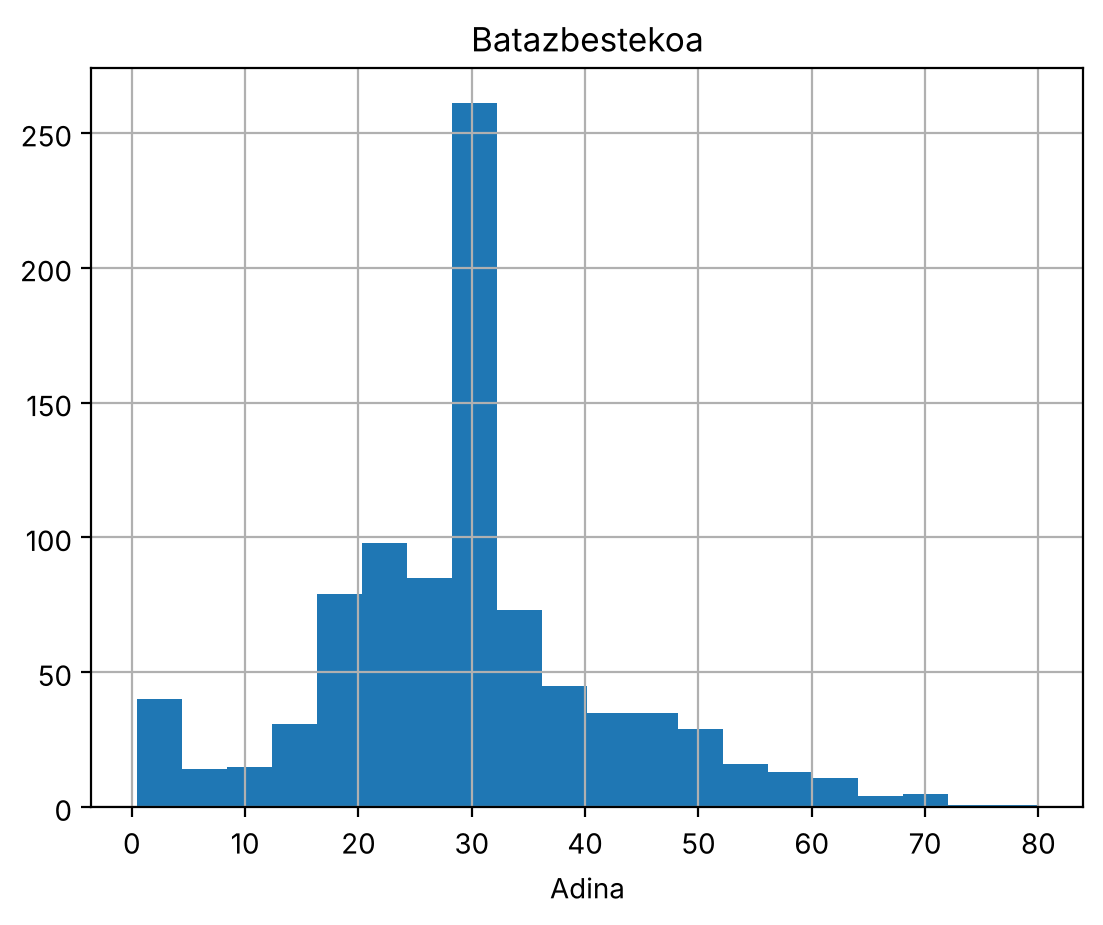

In [8]:
# Batezbestekoarekin betetako adina: 29.7 inguruan pikoa agertzen da (177 balio berdin)
age_batez.hist(bins=20)
plt.title("Batazbestekoa")
plt.xlabel("Adina")
plt.show()

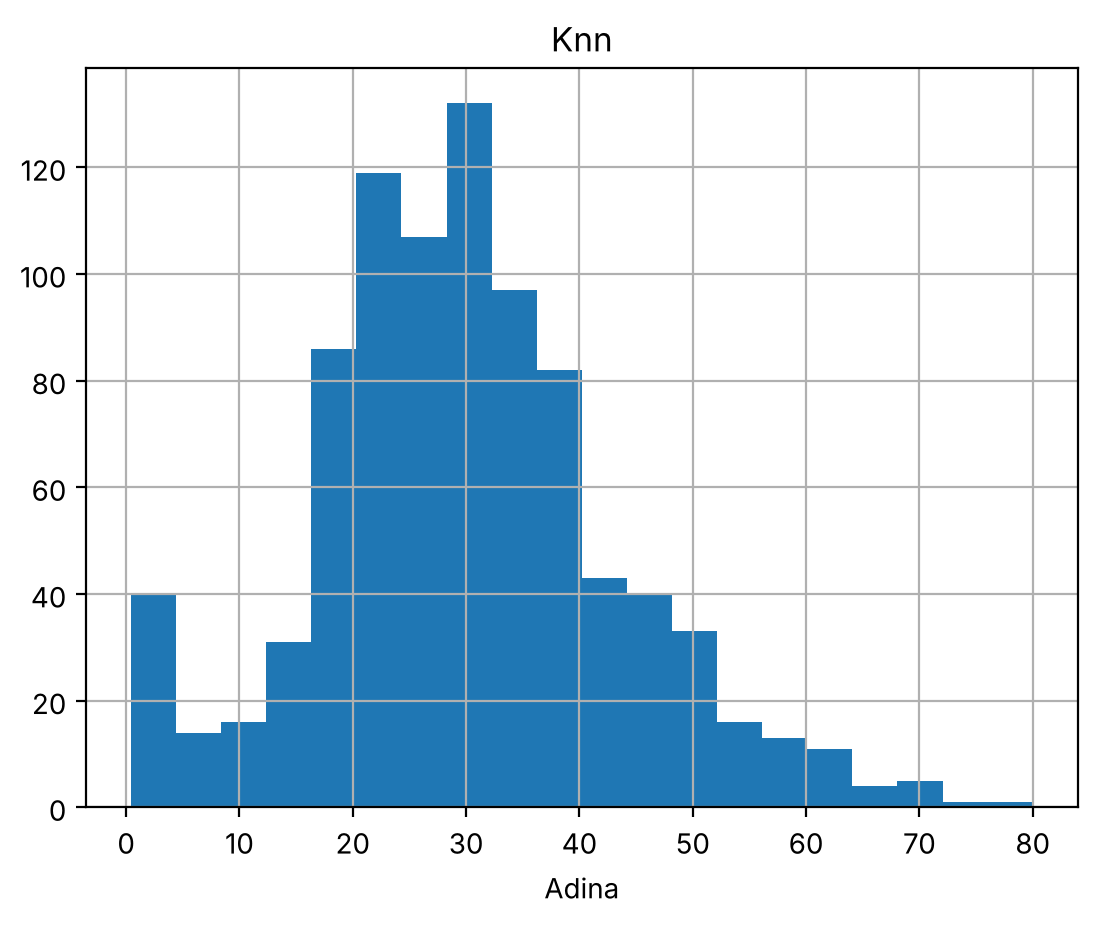

In [9]:
# KNN-rekin betetakoa: ez dago piko artifizialik, jatorrizkoaren antzekoagoa
age_knn.hist(bins=20)
plt.title("Knn")
plt.xlabel("Adina")
plt.show()

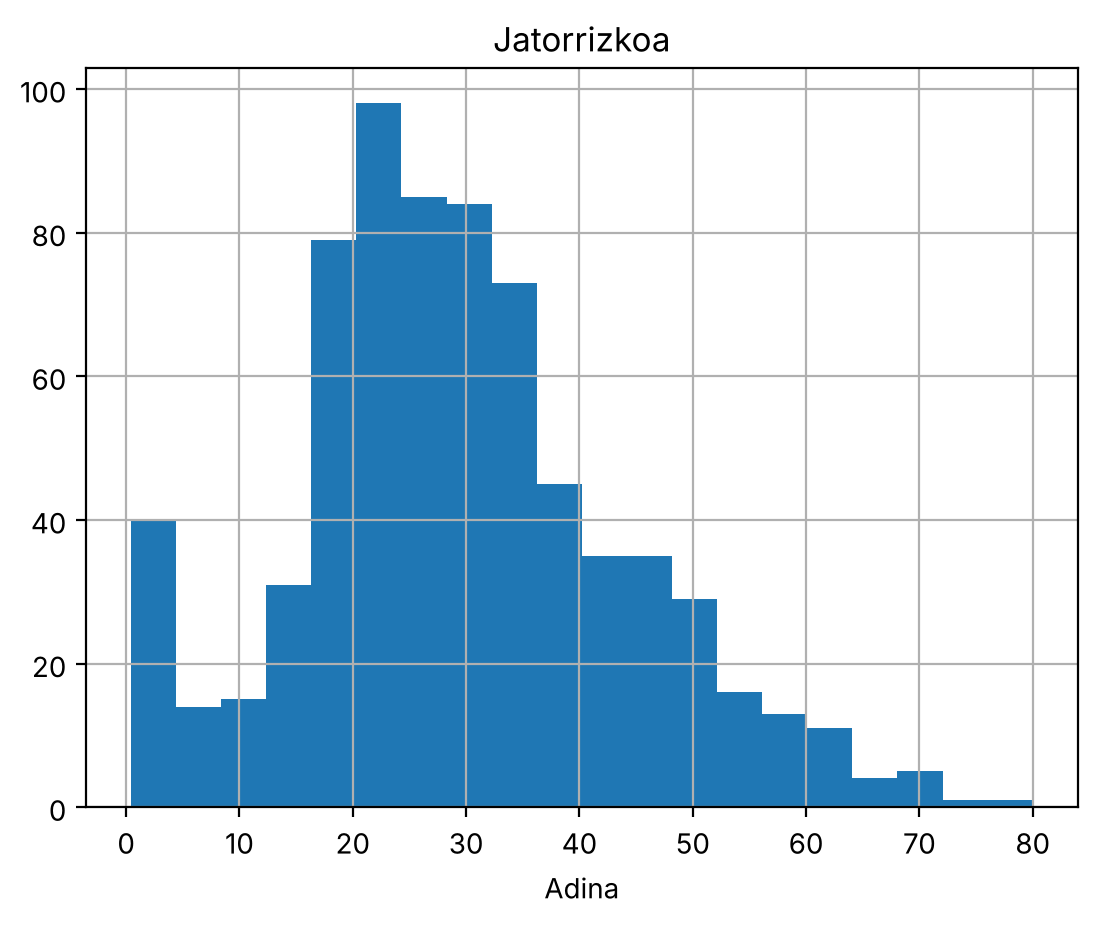

In [10]:
# Jatorrizko adina (NaN gabe, 714 balio)
df["age"].hist(bins=20)
plt.title("Jatorrizkoa")
plt.xlabel("Adina")
plt.show()

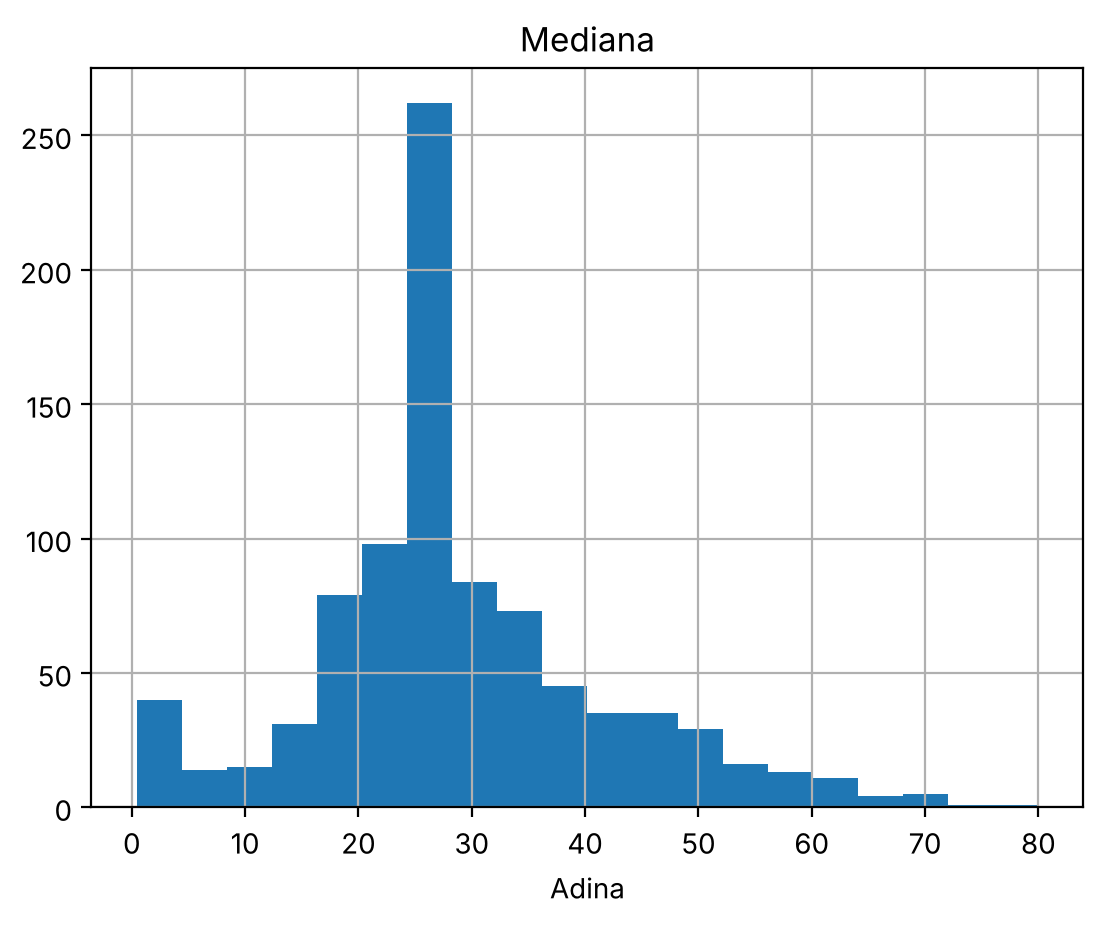

In [11]:
# Medianarekin betetakoa: 28 inguruan pikoa
age_mediana.hist(bins=20)
plt.title("Mediana")
plt.xlabel("Adina")
plt.show()

**Histogramen ondorioa:** batezbestekoa eta mediana erabiltzean balio bakar batean (29.7 / 28) piko artifizial bat sortzen da eta banaketa estutu egiten da (std txikiagoa). KNN-k balio desberdinak ematen ditu bidaiariaren beste ezaugarrien arabera, eta jatorrizko banaketaren forma hobeto mantentzen du.